# Isolation Forest — diagnóstico independente de teclados USB
**CATMAT 451817 · padrão · com fio · por unidade**

Pergunta: **a floresta atribui a mesma medida a todos os teclados ou os resultados viram 100 na conversão para o Score?**

Este experimento usa somente o grupo de teclado, sem Autoencoder, API, PostgreSQL ou publicação.
Compara **preço** com **preço + quantidade**, usando as funções de transformação e de percentil do próprio projeto.
O treino fica congelado em jul–dez/2025; avaliação em jul–ago/2026; setembro/2026 é uma observação posterior adicional, sem ajuste dos modelos.

**Limites:** setembro contém referências dos CSVs `material`, não uma reprodução dos resultados da tela/banco.
Dados tecnicamente elegíveis não são uma comprovação de equivalência comercial ou rótulos de anomalia.
Não excluímos preços extremos para fazer o gráfico ficar melhor.

Execute **Restart Kernel and Run All / Reiniciar kernel e executar tudo**. As células já incluem os resultados da execução entregue.

## 1. Ambiente e funções do projeto
O notebook encontra a raiz do repositório automaticamente. Não abre `.env`, não se conecta ao banco e não carrega modelos serializados.
As saídas locais vão exclusivamente para `data/experimentos/if_teclado/`.

In [1]:
from pathlib import Path
from datetime import date
from decimal import Decimal
from importlib.metadata import version
import csv
import hashlib
import json
import math
import sys
import io
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.ensemble import IsolationForest
from scipy.stats import spearmanr

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'ml/src/licita_ml').is_dir())
EXP = ROOT / 'experimentos/if_teclado'
OUT = ROOT / 'data/experimentos/if_teclado'
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'ml/src'))
from licita_ml.experiments.evaluate import features, train_reference
from licita_ml.inference.registry import percentile

plt.rcParams.update({'figure.figsize': (12, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 80)
SEED = 42
TREES = 200
TRAIN_END = date(2025, 12, 31)
VERSIONS = {p: version(p) for p in ['scikit-learn', 'numpy', 'scipy', 'pandas', 'matplotlib']}
print('Versões efetivamente usadas:', VERSIONS)
print('Apenas saídas do experimento:', OUT.relative_to(ROOT))

Versões efetivamente usadas: {'scikit-learn': '1.9.1', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '3.1.1', 'matplotlib': '3.11.2'}
Apenas saídas do experimento: data/experimentos/if_teclado


## 2. Recorte rastreável, conferido contra os CSVs originais
`recorte_teclado.csv` contém 311 registros da coorte técnica V2: 254 de treino, 44 de avaliação e 13 referências de setembro.
`origem.json` registra a assinatura completa do grupo, períodos, hashes dos ZIPs e hash do recorte.
Os IDs não foram selecionados pelo resultado do IF. Cada linha inclui arquivo, membro e posição para auditoria.
O recorte portátil permite executar o notebook sem os grandes Parquets locais de preparação.

In [2]:
manifest = json.loads((EXP / 'origem.json').read_text())
assert hashlib.sha256((EXP / 'recorte_teclado.csv').read_bytes()).hexdigest() == manifest['recorte_sha256']
with (EXP / 'recorte_teclado.csv').open(newline='') as f:
    source = list(csv.DictReader(f, delimiter=';'))
assert len(source) == 311
assert len({r['id_observacao'] for r in source}) == len(source)
assert {r['catalogo'] for r in source} == {'451817'}
assert {r['grupo'] for r in source} == {manifest['grupo']}
assert {r['sigla_unidade_fornecimento'].upper() for r in source} == {'UN'}
parts = {name: sorted([r for r in source if r['conjunto'] == name],
                     key=lambda r: r['id_observacao']) for name in manifest['contagens']}
for name, rows in parts.items():
    assert len(rows) == manifest['contagens'][name]
    for r in rows:
        assert Decimal(r['preco_unitario']) > 0 and Decimal(r['quantidade']) > 0
        assert date.fromisoformat(r['data_compra']) <= date.fromisoformat(r['data_resultado'])
        start, end = {'treino': ('2025-07-01', '2025-12-31'),
                      'avaliacao': ('2026-07-01', '2026-08-31'),
                      'setembro': ('2026-09-01', '2026-09-30')}[name]
        assert start <= r['data_compra'] <= r['data_resultado'] <= end
assert not ({r['compra'] for r in parts['treino']} & {r['compra'] for r in parts['avaliacao']})
frame = pd.DataFrame(source)
for c in ['preco_unitario', 'quantidade']:
    frame[c] = frame[c].astype(float)  # apenas visualização; o modelo recebe Decimal abaixo
count_table = pd.DataFrame([
    {'conjunto': name, 'registros': len(rows), 'compras_distintas': len({r['compra'] for r in rows}),
     'primeiro_resultado': min(r['data_resultado'] for r in rows),
     'ultimo_resultado': max(r['data_resultado'] for r in rows)} for name, rows in parts.items()
])
display(count_table)
print('Grupo:', manifest['descricao'])

,conjunto,registros,compras_distintas,primeiro_resultado,ultimo_resultado
0,treino,254,250,2025-07-01,2025-12-31
1,avaliacao,44,44,2026-07-13,2026-08-31
2,setembro,13,13,2026-09-02,2026-09-30


Grupo: Teclado padrão, USB, com fio, por unidade


## 3. Conferência independente das 311 linhas na origem
A célula abaixo percorre os nove ZIPs originais usados neste recorte, confere seus hashes e verifica preço, quantidade, CATMAT,
unidade e descrições nas posições registradas. É a etapa mais demorada, mas não treina nem modifica dados.
Se os ZIPs não estiverem presentes, a execução para: não substituímos a conferência por dados artificiais.

In [3]:
checked = 0
for original in manifest['fontes']:
    archive = ROOT / original['arquivo']
    assert archive.is_file(), f'Arquivo original necessário: {archive}'
    with archive.open('rb') as f:
        assert hashlib.file_digest(f, 'sha256').hexdigest() == original['sha256']
    selected = {int(r['linha']): r for r in source if r['arquivo_sha256'] == original['sha256']}
    seen = set()
    with zipfile.ZipFile(archive) as z:
        member = next(iter(selected.values()))['membro']
        reader = csv.DictReader(io.TextIOWrapper(z.open(member), encoding='utf-8-sig'), delimiter=';')
        for line_no, raw in enumerate(reader, 2):
            if line_no in selected:
                r = selected[line_no]
                for key in ['preco_unitario', 'quantidade']:
                    assert Decimal(raw[key]) == Decimal(r[key])
                assert raw['codigo_item_catalogo'] == r['catalogo']
                for key in ['descricao_item', 'descricao_detalhada_item', 'marca',
                            'sigla_unidade_fornecimento', 'capacidade_unidade_fornecimento',
                            'sigla_unidade_medida', 'data_compra', 'data_resultado']:
                    assert raw[key] == r[key], (member, line_no, key)
                seen.add(line_no)
            if line_no >= max(selected):
                break
    assert seen == set(selected)
    checked += len(seen)
    print(f'{member}: {len(seen)} registros conferidos')
assert checked == len(source)
print(f'OK: {checked} registros reconciliados com a origem.')

material_2025_07.csv: 29 registros conferidos
material_2025_08.csv: 46 registros conferidos
material_2025_09.csv: 49 registros conferidos
material_2025_10.csv: 53 registros conferidos
material_2025_11.csv: 44 registros conferidos
material_2025_12.csv: 33 registros conferidos
material_2026_07.csv: 25 registros conferidos
material_2026_08.csv: 19 registros conferidos
material_2026_09.csv: 13 registros conferidos
OK: 311 registros reconciliados com a origem.


## 4. Antes da ML: distribuição e registros que exigem revisão
A mediana e os intervalos vêm dos dados, não de um preço de mercado consultado externamente.
Valores extremos permanecem na coorte. A descrição genérica pode esconder modelos ou escopos diferentes.
Não classificar automaticamente um registro extremo como fraude, sobrepreço ou erro confirmado.

,count,mean,std,min,25%,50%,75%,95%,max
conjunto,,,,,,,,,
avaliacao,44.0,34.736,36.139,15.77,19.298,25.7,32.535,62.229,216.18
treino,254.0,214.162,2589.065,14.99,19.500,22.8,31.360,90.624,41046.90
setembro,13.0,26.947,17.980,14.80,19.200,20.0,29.000,53.180,84.20


,conjunto,preco_unitario,quantidade,marca,descricao_detalhada_item,membro,linha
173,treino,41046.90,1.0,NET ALFA,"Teclado Microcomputador tipo: padrão, tipo conector: usb, conectividade: com...",material_2025_09.csv,34573
4,treino,4669.80,1.0,DEACOM INFORMATICA LTDA,"Teclado Microcomputador conectividade: com fio, tipo: padrão, tipo conector:...",material_2025_11.csv,49942
230,treino,710.00,2.0,DELL,"TECLADO MICROCOMPUTADOR, TIPO PADRÃO, TIPO CONECTOR USB, CONECTIVIDADE COM FIO",material_2025_12.csv,111650
200,avaliacao,216.18,2.0,-,"Teclado Microcomputador conectividade: com fio, tipo: padrão, tipo conector:...",material_2026_08.csv,85674
163,treino,201.53,20.0,KNUP/KNUP,"TECLADO MICROCOMPUTADOR, TIPO PADRÃO, TIPO CONECTOR USB, CONECTIVIDADE COM FIO",material_2025_08.csv,128248
102,treino,199.75,15.0,LOGITECH,"Teclado Microcomputador conectividade: com fio, tipo: padrão, tipo conector:...",material_2025_10.csv,170645
66,avaliacao,160.00,3.0,Generico,"Teclado Microcomputador tipo: padrão, tipo conector: usb, conectividade: com...",material_2026_08.csv,80575
247,treino,125.80,1.0,TECLADO MICROCOMPUTA,"TECLADO MICROCOMPUTADOR, TIPO PADRÃO, TIPO CONECTOR USB, CONECTIVIDADE COM FIO",material_2025_09.csv,149584


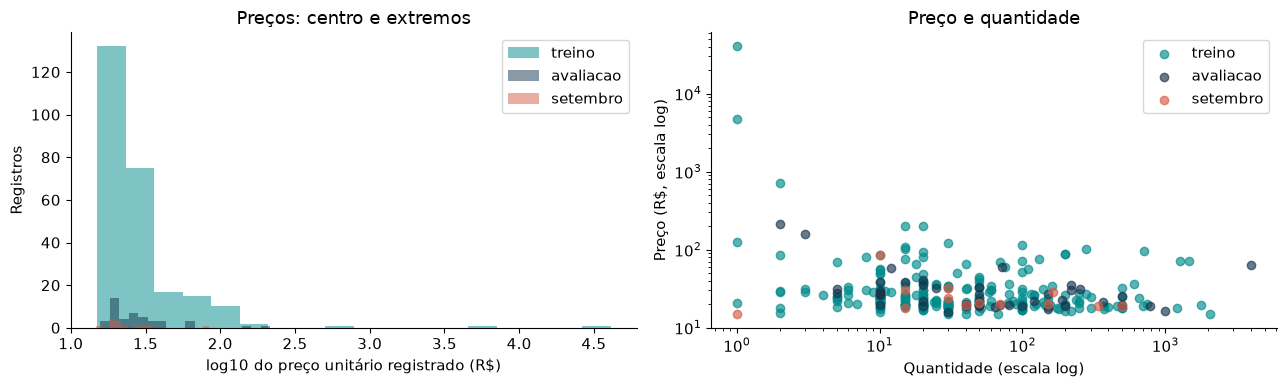

In [4]:
display(frame.groupby('conjunto', sort=False)['preco_unitario'].describe(percentiles=[.25, .5, .75, .95]).round(3))
display(frame.sort_values('preco_unitario', ascending=False)[
    ['conjunto', 'preco_unitario', 'quantidade', 'marca', 'descricao_detalhada_item', 'membro', 'linha']
].head(8))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, color in [('treino', '#008B8B'), ('avaliacao', '#17344E'), ('setembro', '#D85B45')]:
    f = frame[frame.conjunto == name]
    axes[0].hist(np.log10(f.preco_unitario), bins=18, alpha=.5, label=name, color=color)
    axes[1].scatter(f.quantidade, f.preco_unitario, alpha=.65, label=name, color=color)
axes[0].set(xlabel='log10 do preço unitário registrado (R$)', ylabel='Registros', title='Preços: centro e extremos')
axes[1].set(xscale='log', yscale='log', xlabel='Quantidade (escala log)',
            ylabel='Preço (R$, escala log)', title='Preço e quantidade')
for ax in axes: ax.legend()
fig.tight_layout(); fig.savefig(OUT / '01_dados.png', dpi=150); plt.show()

## 5. Mesmas transformações do projeto, sem vazamento temporal
**Preço:** `ln(preço / mediana do treino)`; **quantidade:** `ln(1 + quantidade)`.
Chamamos a função `features` do projeto e reconciliamos o resultado com as matrizes congeladas da preparação V2.
A mediana só usa treino. Nenhum parâmetro é escolhido para reduzir os Scores 100 da avaliação.

In [5]:
def model_rows(rows):
    return [{'id': r['id_observacao'], 'price': Decimal(r['preco_unitario']),
             'quantity': Decimal(r['quantidade']), 'date': date.fromisoformat(r['data_compra'])}
            for r in rows]

rows_by_part = {name: model_rows(rows) for name, rows in parts.items()}
median = train_reference(rows_by_part['treino'], train_end=TRAIN_END)
assert median == Decimal(manifest['mediana_treino'])
NAMES = {'preco': ['log_preco_mediana'],
         'preco_quantidade': ['log_preco_mediana', 'log_quantidade']}
for name, rows in parts.items():
    rebuilt = features(rows_by_part[name], median, NAMES['preco_quantidade'])
    frozen = np.array([[float(r['log_preco_mediana']), float(r['log_quantidade'])] for r in rows])
    np.testing.assert_array_equal(rebuilt, frozen)
print('Mediana do treino: R$', median)
print('OK: transformações idênticas às matrizes preparadas do projeto, nos três períodos.')

Mediana do treino: R$ 22.80000000
OK: transformações idênticas às matrizes preparadas do projeto, nos três períodos.


## 6. Treinar dois IFs independentes no mesmo grupo
Parâmetros operacionais: **200 árvores**, **até 256 registros por árvore**, **seed 42**, `contamination="auto"`.
Como temos 254 registros no treino, `max_samples=254`. A profundidade real máxima é 8; o comprimento ajustado pode ser maior.

- `preco`: diagnóstico simplificado, apenas preço.
- `preco_quantidade`: mesmas entradas da configuração operacional do projeto.

A medida bruta usada aqui é `-score_samples`: **maior = mais anômalo**.
O Score da aplicação é o percentil empírico dessa medida no treino, incluindo empates. **Não é probabilidade nem `medida × 100`.**

In [6]:
def new_model(seed=SEED):
    return IsolationForest(n_estimators=TREES, max_samples=min(256, len(parts['treino'])),
                           max_features=1.0, contamination='auto', random_state=seed, n_jobs=1)

models = {}
calibrations = {}
tables = []
for label, names in NAMES.items():
    model = new_model()
    x_train = features(rows_by_part['treino'], median, names)
    model.fit(x_train)
    calibration = -model.score_samples(x_train)
    models[label] = model
    calibrations[label] = calibration
    for name, rows in parts.items():
        raw = -model.score_samples(features(rows_by_part[name], median, names))
        scored = pd.DataFrame(rows)[['id_observacao', 'conjunto', 'compra', 'preco_unitario',
                                     'quantidade', 'marca', 'membro', 'linha']].copy()
        scored['modelo'] = label
        scored['preco_unitario'] = scored.preco_unitario.astype(float)
        scored['quantidade'] = scored.quantidade.astype(float)
        scored['medida_if'] = raw
        scored['score_app'] = [float(percentile(calibration, v)) for v in raw]
        scored['variacao_mediana_pct'] = (scored.preco_unitario / float(median) - 1) * 100
        tables.append(scored)
results = pd.concat(tables, ignore_index=True)
assert np.isfinite(results[['medida_if', 'score_app']].to_numpy()).all()
assert results.score_app.between(0, 100).all()
print('Profundidade real máxima observada:', {k: max(t.tree_.max_depth for t in m.estimators_)
                                             for k, m in models.items()})
print('Modelos treinados somente em memória; nenhum artefato operacional substituído.')

Profundidade real máxima observada: {'preco': 8, 'preco_quantidade': 8}
Modelos treinados somente em memória; nenhum artefato operacional substituído.


## 7. Resultado principal: quantos recebem 100?
Contamos **100 exato na escala quantizada da aplicação**, além de Scores ≥99 e ≥99,995 (que podem aparecer como 100,00 com duas casas).
Valores maiores ou iguais ao máximo da calibração chegam a 100. Contar só o topo do ranking não representa a distribuição completa.
O treino aparece como referência, não como medição de desempenho em dados novos.

In [7]:
def summarize(group):
    return pd.Series({'registros': len(group), 'medidas_distintas': group.medida_if.nunique(),
                      'score_min': group.score_app.min(), 'score_mediano': group.score_app.median(),
                      'score_max': group.score_app.max(), 'quantos_100': int((group.score_app == 100).sum()),
                      'percentual_100': 100 * (group.score_app == 100).mean(),
                      'quantos_ge_99': int((group.score_app >= 99).sum()),
                      'quantos_ge_99_995': int((group.score_app >= 99.995).sum())})
summary = results.groupby(['modelo', 'conjunto'], sort=False).apply(summarize, include_groups=False).reset_index()
display(summary.round(3))
summary.to_csv(OUT / 'resumo.csv', index=False)
results.to_csv(OUT / 'resultados_completos.csv', index=False)
for label in NAMES:
    print('\nMAIORES SCORES —', label, '(somente dados posteriores ao treino)')
    display(results[(results.modelo == label) & (results.conjunto != 'treino')].sort_values(
        ['score_app', 'medida_if'], ascending=False).head(10).round(4))

,modelo,conjunto,registros,medidas_distintas,score_min,score_mediano,score_max,quantos_100,percentual_100,quantos_ge_99,quantos_ge_99_995
0,preco,treino,254.0,163.0,3.543,50.197,100.000,1.0,0.394,3.0,1.0
1,preco,avaliacao,44.0,42.0,3.543,62.008,98.819,0.0,0.000,0.0,0.0
2,preco,setembro,13.0,13.0,3.543,42.913,97.638,0.0,0.000,0.0,0.0
3,preco_quantidade,treino,254.0,237.0,1.181,50.394,100.000,1.0,0.394,3.0,1.0
4,preco_quantidade,avaliacao,44.0,44.0,5.906,52.952,98.425,0.0,0.000,0.0,0.0
5,preco_quantidade,setembro,13.0,13.0,24.409,45.669,98.425,0.0,0.000,0.0,0.0



MAIORES SCORES — preco (somente dados posteriores ao treino)


,id_observacao,conjunto,compra,preco_unitario,quantidade,marca,membro,linha,modelo,medida_if,score_app,variacao_mediana_pct
279,a437859f26d7e4b144fddf79f899614d57b3660e0f467ddfdbf2daf8043e9aa3,avaliacao,92806206000132026,216.18,2.0,-,material_2026_08.csv,85674,preco,0.6910,98.819,848.1579
265,363de2b012e0e4911bfec2f79210cf6a8a5b0c4ce87f1ef8cfaeb707d83fa830,avaliacao,38016906000992026,160.00,3.0,Generico,material_2026_08.csv,80575,preco,0.6526,98.031,601.7544
309,ca75747ca1e6179c5b9e2a6a8c4fedf9afcd9a024a1f4eb392f2a0bd0a50b533,setembro,16029005900012025,14.80,1.0,tr,material_2026_09.csv,14304,preco,0.6156,97.638,-35.0877
256,0b8ab5b6a5a020038498f7852f243b6cb2ad0cd1b3d8c40e214bdd39ea7f4094,avaliacao,9014605003442026,15.77,30.0,Maxprint,material_2026_07.csv,79996,preco,0.5599,94.488,-30.8333
285,be0df46c8b4e1148af4eb40f2b4ad8c5acd364b6d0ead4c4517715d1dce2330d,avaliacao,10212306003112026,59.90,72.0,Intelbras,material_2026_08.csv,38823,preco,0.5439,93.307,162.7193
260,1c62b55839b95c784e48335d7812dc80b496026ce383ea51a3ab3eebde75f37c,avaliacao,92856105900022026,58.99,12.0,Tech,material_2026_07.csv,46100,preco,0.5403,92.913,158.7281
282,b1e32676b0866bf62f614d3bf1cdbaec7379d0d9e7643269068e19364b5ea2bb,avaliacao,8000905900152026,62.64,4000.0,LG,material_2026_07.csv,44574,preco,0.5324,92.126,174.7368
268,46a5718468140f4f4863113d1ca39aef1c5943efa8a6104839e1243e08afb879,avaliacao,7001305900082026,16.11,1000.0,KB-M10BK,material_2026_07.csv,23047,preco,0.5203,88.976,-29.3421
307,89b6fdf5aa81aa28cfa8fd87136da8a92a624ce053fec69dea65862bf159fa28,setembro,78234106000462026,84.20,10.0,MULTILASER,material_2026_09.csv,68429,preco,0.5161,86.614,269.2982
278,a1e4dde31f1c4d49cd70423bb310865404d39f0e727027094d4708be64fa25e5,avaliacao,18012805900062026,40.29,20.0,BLUECASE,material_2026_07.csv,50473,preco,0.5129,84.646,76.7105



MAIORES SCORES — preco_quantidade (somente dados posteriores ao treino)


,id_observacao,conjunto,compra,preco_unitario,quantidade,marca,membro,linha,modelo,medida_if,score_app,variacao_mediana_pct
593,b1e32676b0866bf62f614d3bf1cdbaec7379d0d9e7643269068e19364b5ea2bb,avaliacao,8000905900152026,62.64,4000.0,LG,material_2026_07.csv,44574,preco_quantidade,0.6760,98.425,174.7368
620,ca75747ca1e6179c5b9e2a6a8c4fedf9afcd9a024a1f4eb392f2a0bd0a50b533,setembro,16029005900012025,14.80,1.0,tr,material_2026_09.csv,14304,preco_quantidade,0.6530,98.425,-35.0877
590,a437859f26d7e4b144fddf79f899614d57b3660e0f467ddfdbf2daf8043e9aa3,avaliacao,92806206000132026,216.18,2.0,-,material_2026_08.csv,85674,preco_quantidade,0.6477,98.031,848.1579
576,363de2b012e0e4911bfec2f79210cf6a8a5b0c4ce87f1ef8cfaeb707d83fa830,avaliacao,38016906000992026,160.00,3.0,Generico,material_2026_08.csv,80575,preco_quantidade,0.6277,96.850,601.7544
579,46a5718468140f4f4863113d1ca39aef1c5943efa8a6104839e1243e08afb879,avaliacao,7001305900082026,16.11,1000.0,KB-M10BK,material_2026_07.csv,23047,preco_quantidade,0.6041,96.063,-29.3421
602,e3b4a0fec5440b9d76afaa98aa65d94b686f77808e15c49097232a2f10e37a0f,avaliacao,15813405900632025,19.20,788.0,Teclado microcomputa,material_2026_08.csv,7163,preco_quantidade,0.5377,90.157,-15.7895
587,9e016b49014d827c972224bce901ee12e376b7960ac8d06db98f0491b308b3d1,avaliacao,45390205900172026,25.40,500.0,Teclado,material_2026_08.csv,80103,preco_quantidade,0.5154,87.008,11.4035
603,e561e6242b242cd70040ce18bbba08113e7145fd96dd8937d94900abbafdab47,avaliacao,16017605900122025,35.00,218.0,Vinik,material_2026_08.csv,25731,preco_quantidade,0.5130,86.614,53.5088
596,be0df46c8b4e1148af4eb40f2b4ad8c5acd364b6d0ead4c4517715d1dce2330d,avaliacao,10212306003112026,59.90,72.0,Intelbras,material_2026_08.csv,38823,preco_quantidade,0.5074,85.433,162.7193
618,89b6fdf5aa81aa28cfa8fd87136da8a92a624ce053fec69dea65862bf159fa28,setembro,78234106000462026,84.20,10.0,MULTILASER,material_2026_09.csv,68429,preco_quantidade,0.5013,83.465,269.2982


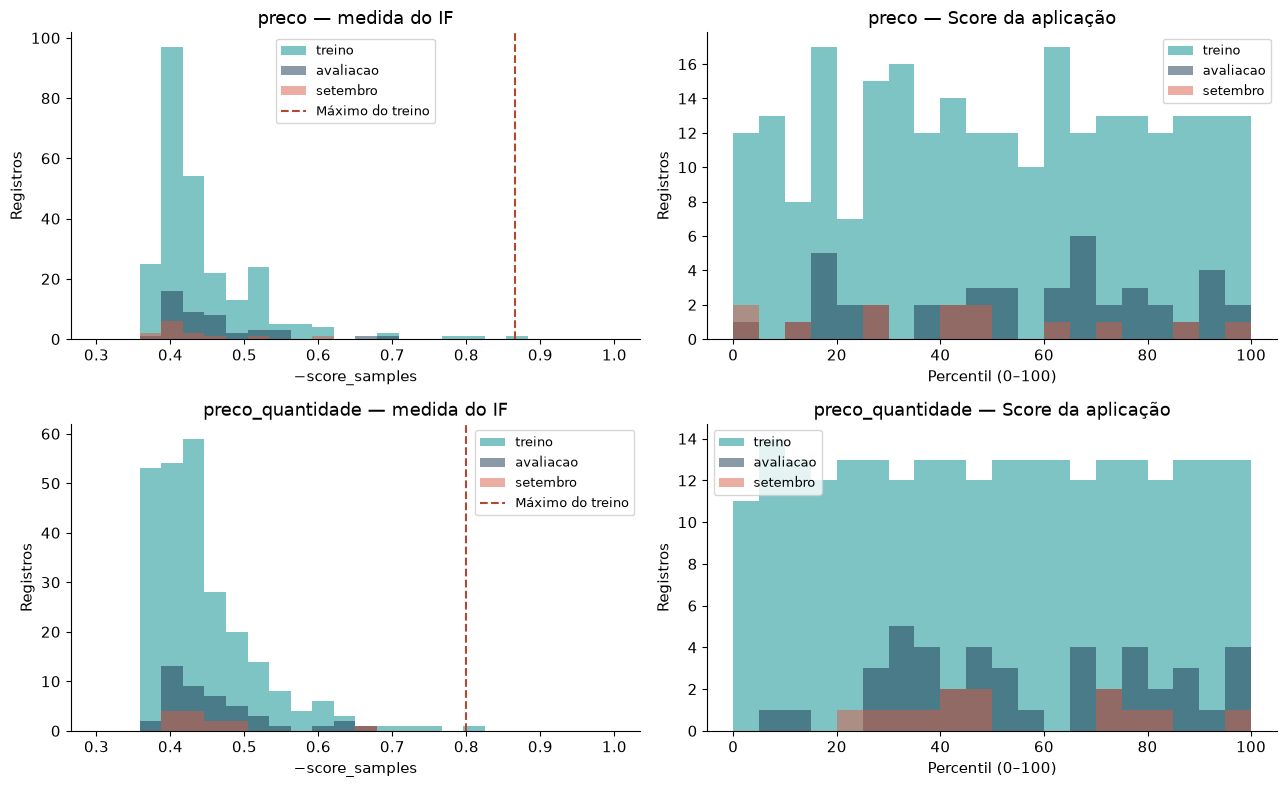

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, label in enumerate(NAMES):
    for name, color in [('treino', '#008B8B'), ('avaliacao', '#17344E'), ('setembro', '#D85B45')]:
        f = results[(results.modelo == label) & (results.conjunto == name)]
        axes[i, 0].hist(f.medida_if, bins=np.linspace(.3, 1, 25), alpha=.5, label=name, color=color)
        axes[i, 1].hist(f.score_app, bins=np.linspace(0, 100, 21), alpha=.5, label=name, color=color)
    axes[i, 0].axvline(calibrations[label].max(), color='#B44732', linestyle='--', label='Máximo do treino')
    axes[i, 0].set(title=label + ' — medida do IF', xlabel='−score_samples', ylabel='Registros')
    axes[i, 1].set(title=label + ' — Score da aplicação', xlabel='Percentil (0–100)', ylabel='Registros')
    for ax in axes[i]: ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig(OUT / '02_medidas_e_scores.png', dpi=150); plt.show()

## 8. Referência estatística simples — não é outro modelo de ML
Usamos `Q1 − 1,5 × IQR` e `Q3 + 1,5 × IQR` sobre **log do preço**, calculados só no treino.
A regra é bilateral (preços baixos ou altos) e serve para comparar sinais. Não é um preço justo nem um rótulo verdadeiro.
Discordar da regra não prova que o IF errou; concordar também não comprova acerto.

In [9]:
train_log = features(rows_by_part['treino'], median, NAMES['preco'])[:, 0]
q1, q3 = np.quantile(train_log, [.25, .75])
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print('Limites exploratórios IQR em preço: R$', round(float(median)*np.exp(lo), 2),
      'até R$', round(float(median)*np.exp(hi), 2))
comparison = results[(results.modelo == 'preco') & (results.conjunto != 'treino')].copy()
logs = np.log(comparison.preco_unitario / float(median))
comparison['sinal_iqr'] = (logs < lo) | (logs > hi)
display(comparison.sort_values('medida_if', ascending=False)[
    ['conjunto', 'preco_unitario', 'quantidade', 'variacao_mediana_pct', 'medida_if', 'score_app', 'sinal_iqr']
].head(15).round(3))
comparison.to_csv(OUT / 'comparacao_iqr.csv', index=False)

Limites exploratórios IQR em preço: R$ 9.56 até R$ 63.95


,conjunto,preco_unitario,quantidade,variacao_mediana_pct,medida_if,score_app,sinal_iqr
279,avaliacao,216.18,2.0,848.158,0.691,98.819,True
265,avaliacao,160.00,3.0,601.754,0.653,98.031,True
309,setembro,14.80,1.0,-35.088,0.616,97.638,False
256,avaliacao,15.77,30.0,-30.833,0.560,94.488,False
285,avaliacao,59.90,72.0,162.719,0.544,93.307,False
260,avaliacao,58.99,12.0,158.728,0.540,92.913,False
282,avaliacao,62.64,4000.0,174.737,0.532,92.126,False
268,avaliacao,16.11,1000.0,-29.342,0.520,88.976,False
307,setembro,84.20,10.0,269.298,0.516,86.614,True
278,avaliacao,40.29,20.0,76.711,0.513,84.646,False


## 9. Testes artificiais separados: preço e quantidade
Abaixo criamos cópias artificiais apenas para sondar os modelos já treinados. Elas não entram no fit nem na calibração.
Fixamos a quantidade em uma linha de teste e depois variamos preço e quantidade independentemente.
O IF não é uma regra linear de sobrepreço: aumentar o preço não obriga a medida a crescer proporcionalmente.
Valores fora do intervalo de treino podem percorrer as mesmas folhas e formar patamares.

,tipo,modelo,preco,quantidade,medida_if,score_app
1,ARTIFICIAL_FORA_DO_TREINO,preco,5.7,30.0,0.61557,97.638
4,ARTIFICIAL_FORA_DO_TREINO,preco,11.4,30.0,0.61557,97.638
7,ARTIFICIAL_FORA_DO_TREINO,preco,22.8,30.0,0.42254,51.575
10,ARTIFICIAL_FORA_DO_TREINO,preco,45.6,30.0,0.52552,90.157
13,ARTIFICIAL_FORA_DO_TREINO,preco,228.0,30.0,0.69619,98.819
16,ARTIFICIAL_FORA_DO_TREINO,preco,2280.0,30.0,0.80807,99.213
19,ARTIFICIAL_FORA_DO_TREINO,preco,228000.0,30.0,0.86589,100.000
22,ARTIFICIAL_FORA_DO_TREINO,preco_quantidade,5.7,30.0,0.50041,83.465
25,ARTIFICIAL_FORA_DO_TREINO,preco_quantidade,11.4,30.0,0.50041,83.465
28,ARTIFICIAL_FORA_DO_TREINO,preco_quantidade,22.8,30.0,0.39074,24.409


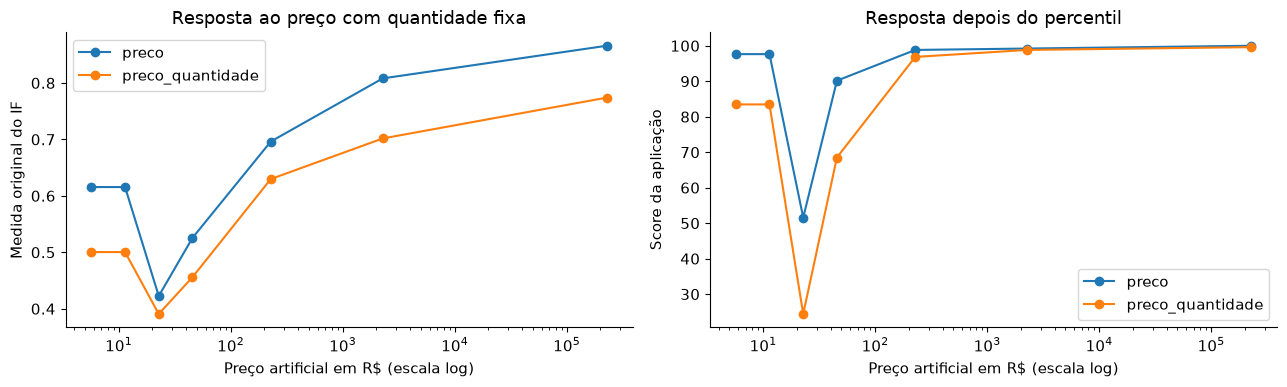

In [10]:
quantity_ref = Decimal(str(np.median([float(r['quantidade']) for r in parts['treino']])))
probe_rows = [{'id': f'ARTIFICIAL-{i}', 'price': median * Decimal(str(mult)),
               'quantity': qty, 'date': TRAIN_END}
              for i, (mult, qty) in enumerate((m, q) for m in [.25, .5, 1, 2, 10, 100, 10000]
                                             for q in [Decimal('1'), quantity_ref, Decimal('10000')])]
probe_tables = []
for label, names in NAMES.items():
    raw = -models[label].score_samples(features(probe_rows, median, names))
    for r, value in zip(probe_rows, raw, strict=True):
        probe_tables.append({'tipo': 'ARTIFICIAL_FORA_DO_TREINO', 'modelo': label,
                             'preco': float(r['price']), 'quantidade': float(r['quantity']),
                             'medida_if': float(value), 'score_app': float(percentile(calibrations[label], value))})
probes = pd.DataFrame(probe_tables)
display(probes[probes.quantidade == float(quantity_ref)].round(5))
probes.to_csv(OUT / 'sondas_artificiais.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label in NAMES:
    f = probes[(probes.modelo == label) & (probes.quantidade == float(quantity_ref))]
    axes[0].plot(f.preco, f.medida_if, 'o-', label=label)
    axes[1].plot(f.preco, f.score_app, 'o-', label=label)
axes[0].set(ylabel='Medida original do IF', title='Resposta ao preço com quantidade fixa')
axes[1].set(ylabel='Score da aplicação', title='Resposta depois do percentil')
for ax in axes: ax.set_xscale('log'); ax.set_xlabel('Preço artificial em R$ (escala log)'); ax.legend()
fig.tight_layout(); fig.savefig(OUT / '03_sondas.png', dpi=150); plt.show()

## 10. Estabilidade entre cinco sementes
Repetimos o treino com sementes fixadas previamente: 11, 23, 42, 71 e 101, sem escolher a que produz a melhor aparência.
Os números de avaliação e setembro são apenas observações, não critérios para ajustar o modelo.
Spearman compara a ordenação com a semente 42, sem medir acurácia.

In [11]:
stability_rows = []
for label, names in NAMES.items():
    x_train = features(rows_by_part['treino'], median, names)
    for seed in [11, 23, 42, 71, 101]:
        m = new_model(seed).fit(x_train)
        cal = -m.score_samples(x_train)
        for name in ['avaliacao', 'setembro']:
            raw = -m.score_samples(features(rows_by_part[name], median, names))
            scores = np.array([float(percentile(cal, x)) for x in raw])
            anchor = results[(results.modelo == label) & (results.conjunto == name)].medida_if.to_numpy()
            corr = float(spearmanr(anchor, raw).statistic) if len(np.unique(raw)) > 1 else None
            stability_rows.append({'modelo': label, 'seed': seed, 'conjunto': name,
                                   'registros': len(raw), 'quantos_100': int((scores == 100).sum()),
                                   'score_mediano': float(np.median(scores)), 'spearman_com_seed42': corr})
stability = pd.DataFrame(stability_rows)
display(stability.round(4))
stability.to_csv(OUT / 'estabilidade.csv', index=False)

,modelo,seed,conjunto,registros,quantos_100,score_mediano,spearman_com_seed42
0,preco,11,avaliacao,44,0,60.4335,0.9813
1,preco,11,setembro,13,0,46.0630,0.9505
2,preco,23,avaliacao,44,0,61.2205,0.9756
3,preco,23,setembro,13,0,45.6690,0.9615
4,preco,42,avaliacao,44,0,62.0080,1.0000
5,preco,42,setembro,13,0,42.9130,1.0000
6,preco,71,avaliacao,44,0,62.7950,0.9877
7,preco,71,setembro,13,0,42.9130,0.9560
8,preco,101,avaliacao,44,0,63.3860,0.9865
9,preco,101,setembro,13,0,43.7010,0.9780


## 11. Verificações de consistência do experimento
A mesma semente e os mesmos dados precisam reproduzir as medidas.
O Score precisa concordar com a contagem empírica do treino. Também verificamos que o modelo só com preço não muda quando alteramos apenas quantidade.
Essas verificações demonstram coerência de implementação; não substituem avaliação comercial dos registros.

In [12]:
for label, names in NAMES.items():
    m = new_model().fit(features(rows_by_part['treino'], median, names))
    x = features(rows_by_part['avaliacao'], median, names)
    np.testing.assert_array_equal(-m.score_samples(x), -models[label].score_samples(x))
    for value in -models[label].score_samples(x):
        expected = (Decimal(int(np.count_nonzero(calibrations[label] <= value))) * 100
                    / len(calibrations[label])).quantize(Decimal('0.001'))
        assert percentile(calibrations[label], value) == expected
    assert percentile(calibrations[label], np.nextafter(calibrations[label].max(), np.inf)) == 100
    assert percentile(calibrations[label], np.nextafter(calibrations[label].min(), -np.inf)) == 0
price_only = probes[probes.modelo == 'preco']
assert price_only.groupby('preco').medida_if.nunique().max() == 1
print('OK: hashes, origem, datas, separação por compra, matrizes, reprodução do fit, percentil e isolamento da quantidade conferidos.')

OK: hashes, origem, datas, separação por compra, matrizes, reprodução do fit, percentil e isolamento da quantidade conferidos.


## 12. Conclusão baseada na execução
A conclusão abaixo é calculada pelos resultados, não escrita presumindo que a floresta funciona.
Não confundir **variação das saídas** com **detecção correta de anomalias comerciais**.

In [13]:
lines = ['### Resultado observado']
for label in NAMES:
    for name in ['avaliacao', 'setembro']:
        f = results[(results.modelo == label) & (results.conjunto == name)]
        n100 = int((f.score_app == 100).sum())
        lines.append(f'- **{label} / {name}: {n100} de {len(f)} em 100**; '
                     f'Scores de {f.score_app.min():.3f} a {f.score_app.max():.3f}; '
                     f'{f.medida_if.nunique()} medidas distintas.')
all100 = bool((results[results.conjunto != 'treino'].score_app == 100).all())
lines += ['', '**Todos os dados novos deram 100? ' + ('SIM.' if all100 else 'NÃO.') + '**',
          '', 'A execução mostra a resposta numérica para este recorte. Não estabelece acurácia, '
          'capacidade de detectar anomalias comerciais ou validade dos registros. Os extremos de origem exigem revisão. '
          'O resultado não reproduz a base SQL nem resolve automaticamente o ranking geral.',
          '', 'Se o IF gera medidas diferentes e o percentil empata resultados, investigar calibração e empates. '
          'Se as medidas também empatam, investigar folhas, características e valores fora do intervalo. '
          'Não alterar a escala apenas para esconder os 100.',
          '', '**Próximo passo:** revisar os registros extremos e equivalência dos teclados; '
          'depois confrontar esta saída com os resultados do mesmo grupo na base operacional, em uma tarefa separada.']
conclusion = '\n'.join(lines)
display(Markdown(conclusion))
(OUT / 'conclusao.md').write_text(conclusion + '\n')
(OUT / 'execucao.json').write_text(json.dumps({'versoes': VERSIONS, 'seed': SEED, 'arvores': TREES,
    'max_samples': min(256, len(parts['treino'])), 'mediana_treino': str(median),
    'recorte_sha256': manifest['recorte_sha256'], 'origem_confirmada': checked,
    'todos_dados_novos_100': all100}, ensure_ascii=False, indent=2))
print('Arquivos locais gerados:', ', '.join(p.name for p in sorted(OUT.iterdir()) if p.is_file()))

### Resultado observado
- **preco / avaliacao: 0 de 44 em 100**; Scores de 3.543 a 98.819; 42 medidas distintas.
- **preco / setembro: 0 de 13 em 100**; Scores de 3.543 a 97.638; 13 medidas distintas.
- **preco_quantidade / avaliacao: 0 de 44 em 100**; Scores de 5.906 a 98.425; 44 medidas distintas.
- **preco_quantidade / setembro: 0 de 13 em 100**; Scores de 24.409 a 98.425; 13 medidas distintas.

**Todos os dados novos deram 100? NÃO.**

A execução mostra a resposta numérica para este recorte. Não estabelece acurácia, capacidade de detectar anomalias comerciais ou validade dos registros. Os extremos de origem exigem revisão. O resultado não reproduz a base SQL nem resolve automaticamente o ranking geral.

Se o IF gera medidas diferentes e o percentil empata resultados, investigar calibração e empates. Se as medidas também empatam, investigar folhas, características e valores fora do intervalo. Não alterar a escala apenas para esconder os 100.

**Próximo passo:** revisar os registros extremos e equivalência dos teclados; depois confrontar esta saída com os resultados do mesmo grupo na base operacional, em uma tarefa separada.

Arquivos locais gerados: 01_dados.png, 02_medidas_e_scores.png, 03_sondas.png, comparacao_iqr.csv, conclusao.md, estabilidade.csv, execucao.json, resultados_completos.csv, resumo.csv, sondas_artificiais.csv


## Referências e arquivos do projeto
- [Isolation Forest — documentação oficial](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)
- Transformações e treino: `ml/src/licita_ml/experiments/evaluate.py`.
- Conversão em percentil: `ml/src/licita_ml/inference/registry.py::percentile`.
- Origem e critérios da coorte: `origem.json`, `recorte_teclado.csv` e a preparação temporal V2.

**O que não fazemos:** usar setembro para treinar, declarar erro de cadastro só pelo preço, excluir extremos sem justificativa documental,
combinar Scores de algoritmos diferentes ou publicar modelos/resultados no sistema.